In [17]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/aptos2019-blindness-detection/sample_submission.csv
/kaggle/input/competitions/aptos2019-blindness-detection/train.csv
/kaggle/input/competitions/aptos2019-blindness-detection/test.csv
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/ef476be214d4.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/6dcde47060f9.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/ec363f48867b.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/17f6c7072f61.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/b49b2fac2514.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/af6166d57f13.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/8d13c46e7d75.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/c3b15bf9b4bc.png
/kaggle/input/competitions/aptos2019-blindness-detection/train_images/be68322c7223.png
/kagg

In [18]:
import pandas as pd

df = pd.read_csv("/kaggle/input/competitions/aptos2019-blindness-detection/train.csv")
print(df.shape)
print(df["diagnosis"].value_counts().sort_index())

(3662, 2)
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


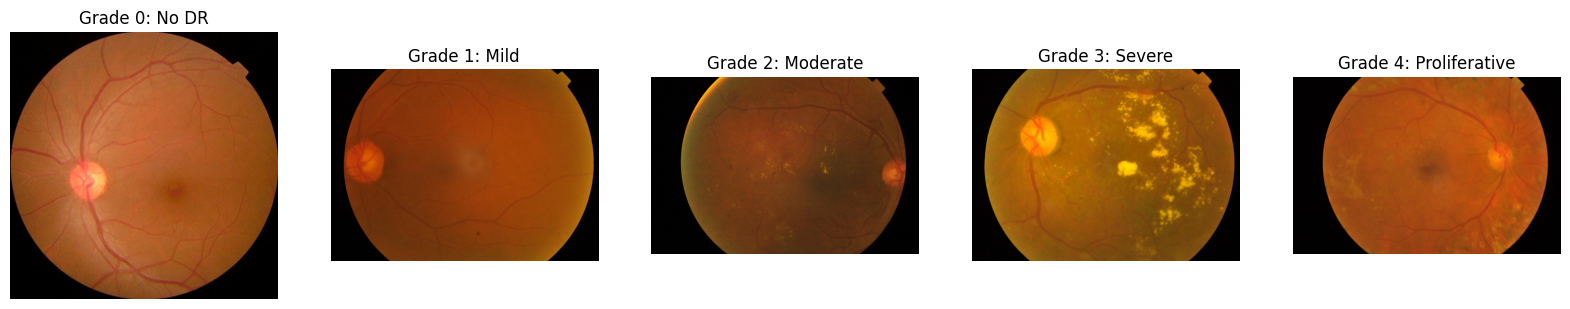

In [19]:
import matplotlib.pyplot as plt
from PIL import Image

base = "/kaggle/input/competitions/aptos2019-blindness-detection/train_images/"
names = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for grade in range(5):
    row = df[df["diagnosis"] == grade].iloc[0]
    img = Image.open(base + row["id_code"] + ".png")
    axes[grade].imshow(img)
    axes[grade].set_title(f"Grade {grade}: {names[grade]}")
    axes[grade].axis("off")
plt.show()

In [20]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["diagnosis"], random_state=42)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["diagnosis"], random_state=42)

print(len(train_df), len(val_df), len(test_df))
print(test_df["diagnosis"].value_counts().sort_index())

train_df.to_csv("train_split.csv", index=False)
val_df.to_csv("val_split.csv", index=False)
test_df.to_csv("test_split.csv", index=False)

2563 549 550
diagnosis
0    271
1     56
2    150
3     29
4     44
Name: count, dtype: int64


In [21]:
import torch

print("GPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU available: True
GPU name: Tesla T4


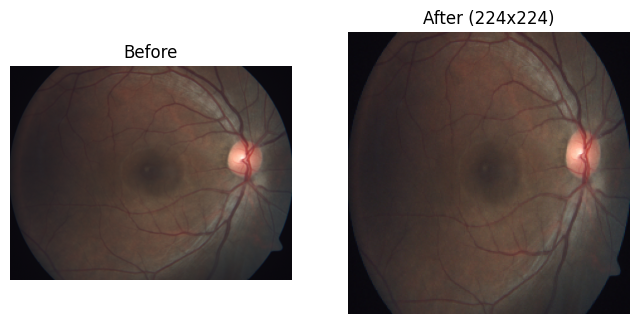

In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = 224
base = "/kaggle/input/competitions/aptos2019-blindness-detection/train_images/"

def crop_black(img, tol=7):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = gray > tol
    if mask.sum() == 0:
        return img
    ys, xs = np.where(mask)
    return img[ys.min():ys.max()+1, xs.min():xs.max()+1]

def load_image(id_code):
    img = cv2.imread(base + id_code + ".png")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = crop_black(img)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    return img

# check on one image: before and after
code = train_df.iloc[0]["id_code"]
before = cv2.cvtColor(cv2.imread(base + code + ".png"), cv2.COLOR_BGR2RGB)
after = load_image(code)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(before); axes[0].set_title("Before"); axes[0].axis("off")
axes[1].imshow(after); axes[1].set_title("After (224x224)"); axes[1].axis("off")
plt.show()

In [23]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

train_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

eval_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class DRDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = load_image(row["id_code"])
        img = self.transform(img)
        return img, int(row["diagnosis"])

train_loader = DataLoader(DRDataset(train_df, train_tf), batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(DRDataset(val_df, eval_tf), batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(DRDataset(test_df, eval_tf), batch_size=32, shuffle=False, num_workers=2)

images, labels = next(iter(train_loader))
print(images.shape, labels[:10])

torch.Size([32, 3, 224, 224]) tensor([0, 0, 2, 0, 0, 0, 2, 0, 0, 4])


In [24]:
import glob
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# find the weights file you uploaded
path = glob.glob("/kaggle/input/**/efficientnet_b0_rwightman*.pth", recursive=True)
print("Weights file:", path)

# build EfficientNet-B0 and load the pretrained weights from the file
model = models.efficientnet_b0(weights=None)
model.load_state_dict(torch.load(path[0], map_location="cpu"))

# replace the last layer: 5 outputs, one for each DR grade
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 5)

# freeze the pretrained part, so only the new last layer learns first
for p in model.features.parameters():
    p.requires_grad = False

model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print("Device:", device)
print(f"Trainable parameters: {trainable:,} of {total:,}")

Weights file: ['/kaggle/input/datasets/gangalakshmik/efficientnet-b0-rwightman-7f5810bc-pth/efficientnet_b0_rwightman-7f5810bc.pth']
Device: cuda
Trainable parameters: 6,405 of 4,013,953


In [26]:
import numpy as np
from sklearn.metrics import accuracy_score, cohen_kappa_score

# class weights: rare grades count more
counts = train_df["diagnosis"].value_counts().sort_index().values
weights = len(train_df) / (5 * counts)
class_weights = torch.tensor(weights, dtype=torch.float).to(device)
print("Class weights:", weights.round(2))

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=1e-3)

def run_epoch(loader, train=True):
    if train:
        model.train()
        model.features.eval()   # keep the frozen part unchanged
    else:
        model.eval()
    preds, trues = [], []
    with torch.set_grad_enabled(train):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            out = model(imgs)
            loss = criterion(out, labels)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            preds += out.argmax(1).cpu().tolist()
            trues += labels.cpu().tolist()
    acc = accuracy_score(trues, preds)
    kappa = cohen_kappa_score(trues, preds, weights="quadratic")
    return acc, kappa

for epoch in range(1, 6):
    ta, tk = run_epoch(train_loader, True)
    va, vk = run_epoch(val_loader, False)
    print(f"Epoch {epoch}: train acc {ta:.3f} | val acc {va:.3f} | val kappa {vk:.3f}")

Class weights: [0.41 1.98 0.73 3.8  2.48]
Epoch 1: train acc 0.698 | val acc 0.741 | val kappa 0.747
Epoch 2: train acc 0.726 | val acc 0.736 | val kappa 0.788
Epoch 3: train acc 0.740 | val acc 0.763 | val kappa 0.788
Epoch 4: train acc 0.748 | val acc 0.745 | val kappa 0.782
Epoch 5: train acc 0.743 | val acc 0.743 | val kappa 0.793


In [ ]:
# unfreeze every layer
for p in model.parameters():
    p.requires_grad = True

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

def run_epoch_ft(loader, train=True):
    model.train() if train else model.eval()
    preds, trues = [], []
    with torch.set_grad_enabled(train):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            out = model(imgs)
            loss = criterion(out, labels)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            preds += out.argmax(1).cpu().tolist()
            trues += labels.cpu().tolist()
    return accuracy_score(trues, preds), cohen_kappa_score(trues, preds, weights="quadratic")

best_kappa = 0
for epoch in range(1, 11):
    ta, tk = run_epoch_ft(train_loader, True)
    va, vk = run_epoch_ft(val_loader, False)
    msg = ""
    if vk > best_kappa:
        best_kappa = vk
        torch.save(model.state_dict(), "/kaggle/working/efficientnet_b0_dr.pth")
        msg = "  <- saved best"
    print(f"Epoch {epoch}: train acc {ta:.3f} | val acc {va:.3f} | val kappa {vk:.3f}{msg}")

In [29]:
import os
p = "/kaggle/working/efficientnet_b0_dr.pth"
print("Saved model exists:", os.path.exists(p))
if os.path.exists(p):
    print("Size (MB):", round(os.path.getsize(p) / 1e6, 1))

Saved model exists: True
Size (MB): 16.4


In [30]:
from sklearn.metrics import classification_report, confusion_matrix

model.load_state_dict(torch.load("/kaggle/working/efficientnet_b0_dr.pth", map_location=device))
model.eval()

def predict(loader):
    preds, trues = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            out = model(imgs.to(device))
            preds += out.argmax(1).cpu().tolist()
            trues += labels.tolist()
    return trues, preds

vt, vp = predict(val_loader)
print("Safety check, validation kappa:", round(cohen_kappa_score(vt, vp, weights="quadratic"), 3))

tt, tp = predict(test_loader)
print("TEST accuracy:", round(accuracy_score(tt, tp), 3))
print("TEST kappa:", round(cohen_kappa_score(tt, tp, weights="quadratic"), 3))
print(classification_report(tt, tp, target_names=["No DR", "Mild", "Moderate", "Severe", "Prolif."]))
print(confusion_matrix(tt, tp))

Safety check, validation kappa: 0.857
TEST accuracy: 0.778
TEST kappa: 0.863
              precision    recall  f1-score   support

       No DR       0.96      0.99      0.97       271
        Mild       0.53      0.73      0.62        56
    Moderate       0.78      0.60      0.68       150
      Severe       0.31      0.59      0.41        29
     Prolif.       0.48      0.30      0.37        44

    accuracy                           0.78       550
   macro avg       0.62      0.64      0.61       550
weighted avg       0.80      0.78      0.78       550

[[267   4   0   0   0]
 [  5  41   9   0   1]
 [  3  29  90  24   4]
 [  0   0   3  17   9]
 [  2   3  13  13  13]]
